## **1. Setup**

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, confusion_matrix, precision_recall_curve, average_precision_score, classification_report

## **2. Load and Clean**

In [2]:
# This file has been double-quoted. Each line is wrapped in an extra pair of quotes and the real internal quotes are escaped as "". This happens when an already quoted CSV is run through a CSV writer a second time.
# To fix it, strip the outer wrapping off each line and unescape the inner quotes. The result then parses as a normal semicolon-delimited file.

with open("TeleCom_Data-2.csv") as f:
  raw_lines = f.read().splitlines()

cleaned_lines = []

for line in raw_lines:
  if line.startswith('"') and line.endswith('"'):
    line = line[1:-1] # strips the outer quotes
  line = line.replace('""', '"') # unescapes the internal quotes
  cleaned_lines.append(line)

with open("_tmp.csv", "w") as f:
  f.write("\n".join(cleaned_lines))

print("Done.")


Done.


In [3]:
raw = pd.read_csv("_tmp.csv", sep=";")
print("Raw shape:", raw.shape)

Raw shape: (41180, 21)


In [4]:
raw.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:
raw.dtypes

,0
age,int64
job,object
marital,object
education,object
default,object
housing,object
loan,object
contact,object
month,object
day_of_week,object


In [6]:
df = raw.drop_duplicates().reset_index(drop=True).copy()
print("After deduplication:", df.shape)

# pdays = 999 is a placeholder for "never contacted before". It is not a real distance.
df["was_contacted_before"] = (df["pdays"] != 999).astype(int)

df["Subscribed"] = (df["y"] == "yes").astype(int)

print(f"Positive rate: {df["Subscribed"].mean():.3%}")

print("\nSubscribed value counts:")

print(df["Subscribed"].value_counts())

After deduplication: (41168, 21)
Positive rate: 11.264%

Subscribed value counts:
Subscribed
0    36531
1     4637
Name: count, dtype: int64


## **3. Feature engineering and train/test split**

In [7]:
numeric_cols = ["age", "campaign", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed", "was_contacted_before"]
# "duration" is dropped because according to the data dictionary, it's only known after the call ends. So, using it as a predictor would leak the outcome.
# raw "pdays" is already replaced above by the binary was_contacted_before flag.
categ_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]

X = df[numeric_cols + categ_cols].copy()
y = df["Subscribed"].values
print("X shape before one-hot:", X.shape)

X = pd.get_dummies(X, columns=categ_cols, drop_first = True)
print("X shape after one-hot:", X.shape)

X shape before one-hot: (41168, 19)
X shape after one-hot: (41168, 52)


In [8]:
X.head()

,age,campaign,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,was_contacted_before,job_blue-collar,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,40,1,0,1.1,93.994,-36.4,4.857,5191.0,0,False,...,True,False,False,False,True,False,False,False,True,False
1,56,1,0,1.1,93.994,-36.4,4.857,5191.0,0,False,...,True,False,False,False,True,False,False,False,True,False
2,45,1,0,1.1,93.994,-36.4,4.857,5191.0,0,False,...,True,False,False,False,True,False,False,False,True,False
3,59,1,0,1.1,93.994,-36.4,4.857,5191.0,0,False,...,True,False,False,False,True,False,False,False,True,False
4,41,1,0,1.1,93.994,-36.4,4.857,5191.0,0,True,...,True,False,False,False,True,False,False,False,True,False


In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print("Train:", X_train.shape, "Positive Rate:", f"{y_train.mean():.3%}")
print("Test:", X_test.shape, "Positive Rate:", f"{y_test.mean():.3%}")

Train: (28817, 52) Positive Rate: 11.264%
Test: (12351, 52) Positive Rate: 11.262%


In [10]:
# The numeric columns need to be standardised first. It will fit only on training data, then the same transformation will be applied to test data. This is the "fit on train, transform train + test" pattern from Lecture 2.
scaler = StandardScaler()

scaler.fit(X_train[numeric_cols])

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Post-scaling training mean:")
print(X_train_scaled[numeric_cols].mean().round(3)) # This should be near 0

print("\nPost-scaling training std:")
print(X_train_scaled[numeric_cols].std().round(3)) # This should be near 1

Post-scaling training mean:
age                    -0.0
campaign               -0.0
previous               -0.0
emp.var.rate            0.0
cons.price.idx          0.0
cons.conf.idx           0.0
euribor3m              -0.0
nr.employed             0.0
was_contacted_before    0.0
dtype: float64

Post-scaling training std:
age                     1.0
campaign                1.0
previous                1.0
emp.var.rate            1.0
cons.price.idx          1.0
cons.conf.idx           1.0
euribor3m               1.0
nr.employed             1.0
was_contacted_before    1.0
dtype: float64


## **4. Logistic regression — Parametric baseline**

In [11]:
# class_weight = "balanced" is used because the data is heavily imbalanced, so the model needs to be told that the minority class matters.
# "liblinear" works well with smaller to medium datasets and supports class weighting.

logR_model = LogisticRegression(max_iter = 2000, class_weight = "balanced", solver = "liblinear", random_state=42)
logR_model.fit(X_train_scaled, y_train)
print("Logistic regression is fitted.")

Logistic regression is fitted.


In [12]:
# At 83%, accuracy is actually below the 89% always-"no" baseline, which is expected and desirable here.
# The model trades raw accuracy to identify the minority (subscribers), which accuracy alone can't reward.
# This is exactly why we evaluate on PR-AUC / recall / precision instead.

print("Training accuracy:", round(logR_model.score(X_train_scaled, y_train), 3))
print("Test accuracy:", round(logR_model.score(X_test_scaled, y_test), 3))

Training accuracy: 0.828
Test accuracy: 0.834


## **5. KNN — Non-parametric comparison; Hyperparameter tuning**

In [13]:
# "cv" is for Cross-validation to respect the class imbalance
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

# KNN's only hyperparameter is k. Small k tends to overfit especially on imbalanced data while large k tends to underfit.
# I'm searching over a grid that goes from small to fairly large, then using 5-fold stratified CV on the training set to pick the best one.
# Test set is held out for the final evaluation.
k_values = [5, 15, 25, 35, 51, 75, 101]
cv_scores = []

for k in k_values:
  knn = KNeighborsClassifier(n_neighbors=k)
  scores = cross_val_score(knn, X_train_scaled, y_train, cv = cv, scoring = "roc_auc", n_jobs = -1)
  mean_score = scores.mean()
  cv_scores.append(scores.mean())
  print(f"k = {k:3d} -> CV ROC-AUC = {mean_score:.4f}")

best_idx = int(np.argmax(cv_scores))
best_k = k_values[best_idx]
print(f"\nBest k = {best_k} with CV ROC-AUC = {cv_scores[best_idx]:.4f}")

k =   5 -> CV ROC-AUC = 0.7197
k =  15 -> CV ROC-AUC = 0.7571
k =  25 -> CV ROC-AUC = 0.7651
k =  35 -> CV ROC-AUC = 0.7688
k =  51 -> CV ROC-AUC = 0.7718
k =  75 -> CV ROC-AUC = 0.7747
k = 101 -> CV ROC-AUC = 0.7776

Best k = 101 with CV ROC-AUC = 0.7776


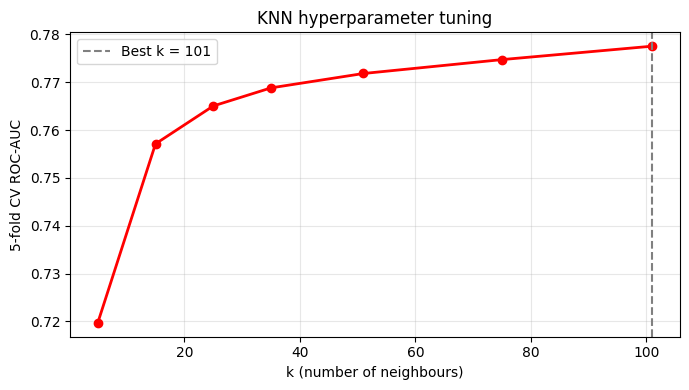

In [14]:
fig, ax = plt.subplots(figsize = (7, 4))
ax.plot(k_values, cv_scores, marker = "o", color = "red", linewidth = 2)
ax.axvline(best_k, linestyle = "--", color = "grey", label = f"Best k = {best_k}")
ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("5-fold CV ROC-AUC")
ax.set_title("KNN hyperparameter tuning")
ax.legend()
ax.grid(alpha = 0.3)
plt.tight_layout()
plt.savefig("fig3_knn_tuning.png", dpi=180, bbox_inches = "tight")
plt.show()

## **6. Cross-validated comparison**

In [15]:
# Here, the two models will be compared on the training set using 5-fold CV, scoring on ROC-AUC (which is robust to class imbalance unlike accuracy).
logR_cv_scores = cross_val_score(logR_model, X_train_scaled, y_train, cv = cv, scoring = "roc_auc", n_jobs = -1)

knn = KNeighborsClassifier(n_neighbors = best_k)
knn_cv_scores = cross_val_score(knn, X_train_scaled, y_train, cv = cv, scoring = "roc_auc", n_jobs = -1)

print(f"Logistic: ROC-AUC = {logR_cv_scores.mean():.4f} (+- {logR_cv_scores.std():.4f})")
print(f"KNN k={best_k}: ROC-AUC = {knn_cv_scores.mean():.4f} (+- {knn_cv_scores.std():.4f})")

Logistic: ROC-AUC = 0.7861 (+- 0.0092)
KNN k=101: ROC-AUC = 0.7776 (+- 0.0082)


## 7. **Test-set evaluation**

In [16]:
# Refitting on full training data
logR_model.fit(X_train_scaled, y_train)
knn.fit(X_train_scaled, y_train)

# Predicted probabilities for the test set
pred_logR = logR_model.predict_proba(X_test_scaled)[:, 1]
pred_knn = knn.predict_proba(X_test_scaled)[:, 1]

# Test-set AUC
auc_logR = roc_auc_score(y_test, pred_logR)
auc_knn = roc_auc_score(y_test, pred_knn)

avgP_logR = average_precision_score(y_test, pred_logR)
avgP_knn = average_precision_score(y_test, pred_knn)

print(f"Logistic: test ROC-AUC = {auc_logR:.4f} / test PR-AUC = {avgP_logR:.4f}")
print(f"KNN k={best_k}: test ROC-AUC = {auc_knn:.4f} / test PR-AUC = {avgP_knn:.4f}")

Logistic: test ROC-AUC = 0.8046 / test PR-AUC = 0.4569
KNN k=101: test ROC-AUC = 0.7939 / test PR-AUC = 0.4511


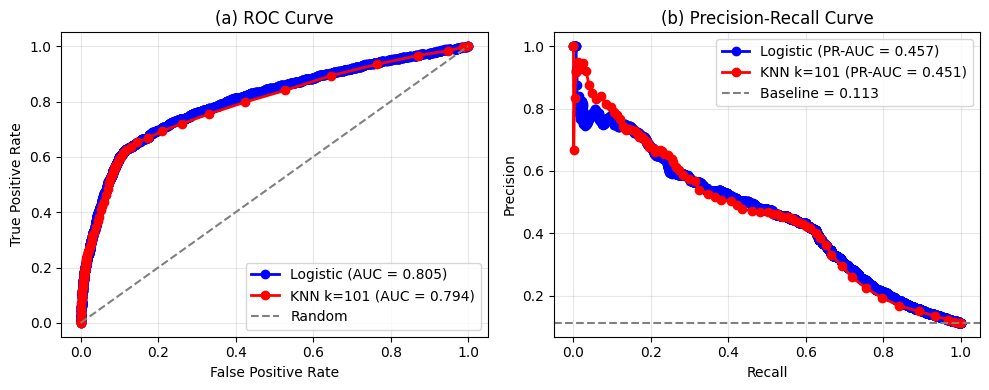

In [17]:
fpr_l, tpr_l, _ = roc_curve(y_test, pred_logR)
fpr_k, tpr_k, _ = roc_curve(y_test, pred_knn)

prec_l, rec_l, _ = precision_recall_curve(y_test, pred_logR)
prec_k, rec_k, _ = precision_recall_curve(y_test, pred_knn)

fig, axes = plt.subplots(1, 2, figsize = (10, 4))


ax = axes[0]
ax.plot(fpr_l, tpr_l, marker = "o", color = "blue", linewidth = 2, label = f"Logistic (AUC = {auc_logR:.3f})")
ax.plot(fpr_k, tpr_k, marker = "o", color = "red", linewidth = 2, label = f"KNN k={best_k} (AUC = {auc_knn:.3f})")

ax.plot([0,1], [0,1], linestyle = "--", color = "grey", label = "Random")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("(a) ROC Curve")

ax.legend(loc = "lower right")
ax.grid(alpha = 0.3)


ax = axes[1]
ax.plot(rec_l, prec_l, marker = "o", color = "blue", linewidth = 2, label = f"Logistic (PR-AUC = {avgP_logR:.3f})")
ax.plot(rec_k, prec_k, marker = "o", color = "red", linewidth = 2, label = f"KNN k={best_k} (PR-AUC = {avgP_knn:.3f})")

ax.axhline(0.113, linestyle = "--", color = "grey", label = "Baseline = 0.113")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("(b) Precision-Recall Curve")

ax.legend(loc = "upper right")
ax.grid(alpha = 0.3)

plt.tight_layout()
plt.savefig("fig1_roc_pr.png", dpi = 180, bbox_inches = "tight")
plt.show()

### **Threshold selection and confusion matrices**

In [18]:
prec, rec, thr = precision_recall_curve(y_test, pred_logR)

denom = np.where((prec + rec) == 0, 1, prec + rec)
f1_scores = 2 * (prec * rec) / denom

best_idx = np.nanargmax(f1_scores [:-1]) # [:-1] because thr has one fewer element than prec/rec
best_thr = thr[best_idx]
print(f"F1-optimal threshold for Logistic: {best_thr:.3f}")

y_hat_logR = (pred_logR >= best_thr).astype(int)
y_hat_knn = (pred_knn >= 0.5).astype(int)

F1-optimal threshold for Logistic: 0.632


In [19]:
print("Logistic Confusion Matrix:")
print(confusion_matrix(y_test, y_hat_logR))

Logistic Confusion Matrix:
[[9864 1096]
 [ 556  835]]


In [20]:
print("Logistic (at F1-optimal threshold):")
print(classification_report(y_test, y_hat_logR))

Logistic (at F1-optimal threshold):
              precision    recall  f1-score   support

           0       0.95      0.90      0.92     10960
           1       0.43      0.60      0.50      1391

    accuracy                           0.87     12351
   macro avg       0.69      0.75      0.71     12351
weighted avg       0.89      0.87      0.88     12351



In [21]:
print("KNN (at default 0.5 threshold):") # KNN is kept at 0.5 for comparison
print(classification_report(y_test, y_hat_knn, digits=3))

KNN (at default 0.5 threshold):
              precision    recall  f1-score   support

           0      0.908     0.986     0.945     10960
           1      0.662     0.211     0.320      1391

    accuracy                          0.899     12351
   macro avg      0.785     0.599     0.633     12351
weighted avg      0.880     0.899     0.875     12351



## **Confusion Matrix**

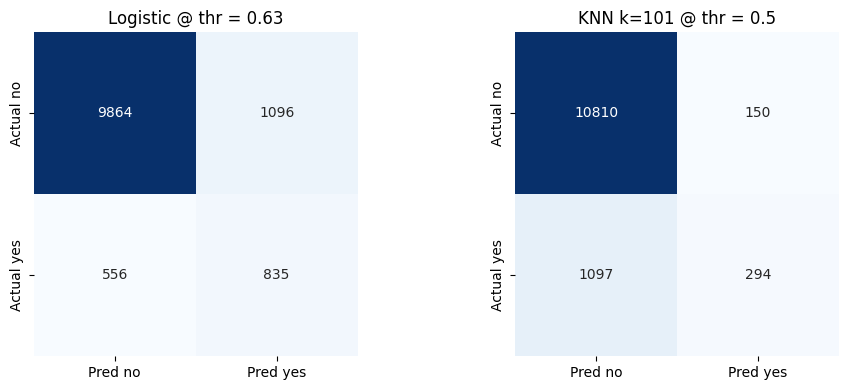

In [22]:
cm_logR = confusion_matrix(y_test, y_hat_logR)
cm_knn = confusion_matrix(y_test, y_hat_knn)

fig, axes = plt.subplots(1, 2, figsize = (10, 4))

sns.heatmap(cm_logR, annot = True, cmap = "Blues", fmt = "d", ax = axes[0], cbar = False, square = True,
            xticklabels = ["Pred no", "Pred yes"], yticklabels = ["Actual no", "Actual yes"])
axes[0].set_title(f"Logistic @ thr = {best_thr:.2f}")

sns.heatmap(cm_knn, annot = True, cmap = "Blues", fmt = "d", ax = axes[1], cbar = False, square = True,
            xticklabels = ["Pred no", "Pred yes"], yticklabels = ["Actual no", "Actual yes"])
axes[1].set_title(f"KNN k={best_k} @ thr = 0.5")

plt.tight_layout()
plt.savefig("fig1_cm.png", dpi = 180, bbox_inches = "tight")
plt.show()

## **8. Inference — Statsmodels Logistic Regression**

In [23]:
X_train_sm = sm.add_constant(X_train_scaled.astype(float))

print("Before dropping:", "\nColumns:", X_train_sm.shape[1], "Rank:", np.linalg.matrix_rank(X_train_sm.values))

X_train_sm = X_train_sm.drop(columns=["housing_unknown"])
print("\nAfter dropping:", "\nColumns:", X_train_sm.shape[1], "Rank:", np.linalg.matrix_rank(X_train_sm.values))

Before dropping: 
Columns: 53 Rank: 52

After dropping: 
Columns: 52 Rank: 52


In [24]:
sm_logR = sm.Logit(y_train, X_train_sm).fit(disp = 0, maxiter = 1000, method = "bfgs")

coef_table = pd.DataFrame({"coefficient": sm_logR.params, "std_error": sm_logR.bse, "p_value": sm_logR.pvalues, "odds_ratio": np.exp(sm_logR.params)})
coef_table = coef_table.sort_values("p_value")

print("Top 15 most significant coefficients:")
print(coef_table.head(15).round(4).to_string())

print("\n\nTop 15 least significant coefficients:")
print(coef_table.tail(15).round(4).to_string())

Top 15 most significant coefficients:
                      coefficient  std_error  p_value  odds_ratio
const                     -2.4972     0.1747   0.0000      0.0823
month_mar                  1.4683     0.1577   0.0000      4.3417
emp.var.rate              -2.1394     0.2338   0.0000      0.1177
contact_telephone         -0.6944     0.0799   0.0000      0.4994
cons.price.idx             1.0610     0.1526   0.0000      2.8893
was_contacted_before       0.2441     0.0450   0.0000      1.2764
month_may                 -0.4136     0.0869   0.0000      0.6613
poutcome_nonexistent       0.4524     0.1034   0.0000      1.5720
month_jun                 -0.5879     0.1346   0.0000      0.5555
campaign                  -0.1205     0.0302   0.0001      0.8865
month_nov                 -0.4548     0.1260   0.0003      0.6346
day_of_week_mon           -0.2268     0.0682   0.0009      0.7971
default_unknown           -0.2191     0.0676   0.0012      0.8033
job_retired                0.3541     

In [25]:
sig_coefs = coef_table.drop("const", errors = "ignore").copy()
sig = sig_coefs[sig_coefs["p_value"] < 0.05].copy()
sig["abs_coef"] = sig["coefficient"].abs()
sig = sig.sort_values("abs_coef", ascending = False).head(15)

print("Top 15 predictors by absolute (standardised) effect size")
print(sig.round(3).to_string())

Top 15 predictors by absolute (standardised) effect size
                      coefficient  std_error  p_value  odds_ratio  abs_coef
emp.var.rate               -2.139      0.234    0.000       0.118     2.139
education_illiterate        1.494      0.704    0.034       4.453     1.494
month_mar                   1.468      0.158    0.000       4.342     1.468
cons.price.idx              1.061      0.153    0.000       2.889     1.061
contact_telephone          -0.694      0.080    0.000       0.499     0.694
poutcome_success            0.597      0.232    0.010       1.818     0.597
month_jun                  -0.588      0.135    0.000       0.556     0.588
month_dec                   0.568      0.223    0.011       1.764     0.568
month_nov                  -0.455      0.126    0.000       0.635     0.455
poutcome_nonexistent        0.452      0.103    0.000       1.572     0.452
month_may                  -0.414      0.087    0.000       0.661     0.414
month_aug                   0.3

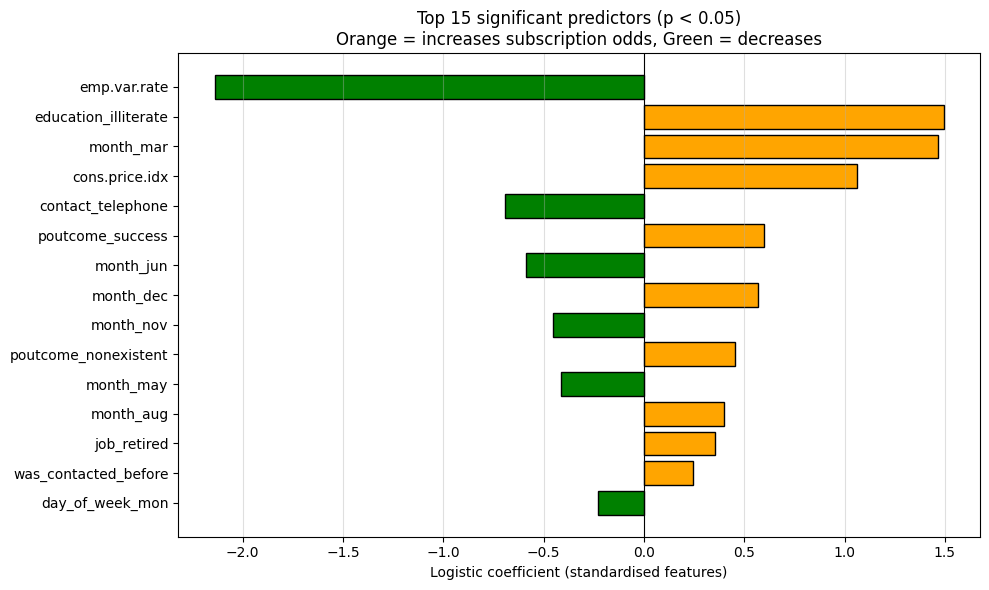

In [26]:
sig_plot = sig.iloc[::-1]

bar_colors = []

for c in sig_plot["coefficient"]:
  if (c > 0):
    bar_colors.append("orange")
  else:
    bar_colors.append("green")

fig, ax = plt.subplots(figsize = (10, 6))

ax.barh(range(len(sig_plot)), sig_plot["coefficient"], color = bar_colors, edgecolor = "black")
ax.set_yticks(range(len(sig_plot)))
ax.set_yticklabels(sig_plot.index, fontsize = 10)
ax.axvline(0, color = "black", linewidth = 0.8)
ax.set_xlabel("Logistic coefficient (standardised features)")
ax.set_title("Top 15 significant predictors (p < 0.05)\nOrange = increases subscription odds, Green = decreases")
ax.grid(axis = "x", alpha = 0.4)
plt.tight_layout()
plt.savefig("fig2_coefs.png", dpi = 180, bbox_inches = "tight")
plt.show()

## **9. Segment subscription rates (Support for the business insights)**

In [27]:
print("Subscription rate by poutcome:")
print(df.groupby("poutcome")["Subscribed"].agg(["mean", "count"]).round(3))

print("\n\nSubscription rate by contact channel:")
print(df.groupby("contact")["Subscribed"].agg(["mean", "count"]).round(3))

print("\n\nSubscription rate by month (sorted):")
print(df.groupby("month")["Subscribed"].agg(["mean", "count"]).sort_values("mean", ascending = False).round(3))

Subscription rate by poutcome:
              mean  count
poutcome                 
failure      0.142   4250
nonexistent  0.088  35547
success      0.651   1371


Subscription rate by contact channel:
            mean  count
contact                
cellular   0.147  26131
telephone  0.052  15037


Subscription rate by month (sorted):
        mean  count
month              
mar    0.505    546
dec    0.489    182
sep    0.449    570
oct    0.439    717
apr    0.205   2631
aug    0.106   6176
jun    0.105   5318
nov    0.101   4096
jul    0.090   7169
may    0.064  13763
